# A burden and spacing surface: two levers at once on three kinds of arm

**Level 2: The method in practice** · Needs: 06-design-response/01-moving-one-lever-at-a-time · Reading time: about 30 minutes

## Objectives

Changing one lever at a time hides how two of them interact. The Design group of the web application shows a response surface over the burden and the spacing, with every model recomputed on the design you change. This notebook builds that surface for one blast and reads what its shape says about each arm.

By the end you will have:

- swept the burden and the spacing of one Akdaglar blast over a 7 by 7 grid, with the product's own `apply_variant`;
- predicted the whole grid with the classical equation, the published regression and a learned arm, and drawn the three surfaces;
- verified the exponent that the classical equation implies for the rock volume, and counted how many distinct values a tree model can produce on the grid.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The Akdaglar blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The variant mechanism and the degenerate-design guard | this repository (MIT) | the product's own licence | `data-pipeline/pipeline/model/blasts.py`, imported by path |
| The case artifact, for the representative blast | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-akdaglar/case.json` |

The sweep factors (0.7 to 1.3) are inputs of this notebook: a range around the base design that stays inside the corpus envelope, not data.

## Method

A grid point is a blast with two multipliers applied: one on the burden-to-diameter ratio (which scales every length of the pattern together, since the diameter is fixed) and one on the spacing-to-burden ratio (which stretches the spacing alone). `apply_variant` applies one multiplier, so two calls apply two. Each perturbed design is checked by `is_degenerate` and then predicted.

For the classical equation the surface has a known form. At a fixed powder factor `V/Q` is constant, so the mean size varies only through `Q^(1/6)`, and `Q` is the powder factor times the rock volume `V = B * S * H`. The slope of the log mean size against the log volume must therefore be 1/6 (Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013). The cell checks that on the grid.

The regression is a power law of the seven ratios (Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957), smooth by construction. A tree ensemble such as gradient boosting (Sui et al. 2025, https://doi.org/10.3390/app15031254) is piecewise constant: it can only return values the leaves hold.

### Step 1: the base design and the grid

The cell takes the representative blast of the Akdaglar case (the first one with a geometry), builds the three arms as in the previous notebook, and lays a 7 by 7 grid of multipliers on the burden ratio and the spacing ratio.

In [2]:
# Imports, the representative blast, the three arms and the grid of multipliers
import dataclasses
import json
import sys
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.cases.fragmenta_cases import Variant
from pipeline.model.blasts import apply_variant, is_degenerate

DERIVED = Path("../../../data/derived")
artifact = json.loads((DERIVED / "real-akdaglar" / "case.json").read_text(encoding="utf-8"))
train = bf.load_training_corpus()
base = next(b for b in train if b.blast_id == artifact["representative_blast_id"])
arms = {
    "kuznetsov": bf.Kuznetsov(dict(bf.SITE_ROCK_FACTOR)),
    "published-regression": bf.PublishedRegression(),
    "xgboost": bf.default_arms()["xgboost"]().fit([b for b in train if b.site != base.site]),
}
factors = np.linspace(0.7, 1.3, 7)
print("base design:", base.blast_id, "|", base.site, "| B/D", base.B_over_D, "| S/B", base.S_over_B)
print("multipliers:", [round(float(f), 2) for f in factors])

base design: Ad1 | Akdaglar | B/D 28.09 | S/B 1.2
multipliers: [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3]


### Step 2: predict the grid

For each pair of multipliers the cell perturbs the base blast twice, checks it is still a blast, reconstructs its volume and predicts it with each arm. A point that is degenerate would be left blank; none is expected inside this range.

In [3]:
# Predict every grid point with every arm and record the rock volume of the perturbed design
surface = {name: np.full((7, 7), np.nan) for name in arms}
volume = np.full((7, 7), np.nan)
for i, burden_factor in enumerate(factors):
    for j, spacing_factor in enumerate(factors):
        step1 = apply_variant(base, Variant("grid-b", "", "", "B_over_D", float(burden_factor)))
        point = apply_variant(step1, Variant("grid-s", "", "", "S_over_B", float(spacing_factor)))
        if is_degenerate(point) is not None:
            continue
        volume[i, j] = bf.reconstruct_pattern(point).rock_volume_m3
        for name, arm in arms.items():
            prediction = arm.predict_one(point)
            if prediction.x50_m is not None:
                surface[name][i, j] = prediction.x50_m
print("grid points predicted by every arm:", int(np.isfinite(np.stack(list(surface.values()))).all(axis=0).sum()), "of 49")
print(f"{'arm':<22}{'min (m)':>10}{'max (m)':>10}{'distinct values':>20}")
for name, grid in surface.items():
    print(f"{name:<22}{np.nanmin(grid):>10.4f}{np.nanmax(grid):>10.4f}{len(np.unique(np.round(grid, 9))):>20}")

grid points predicted by every arm: 49 of 49
arm                      min (m)   max (m)     distinct values
kuznetsov                 0.1705    0.2576                  49
published-regression      0.1341    0.2450                  49
xgboost                   0.2185    0.2870                  17


### Step 3: the exponent of the classical equation

The cell regresses the log of the classical prediction on the log of the rock volume over the 49 points. With the powder factor fixed, the equation implies a slope of exactly 1/6.

In [4]:
# Log-log slope of the classical mean size against the rock volume over the grid
slope = np.polyfit(np.log(volume.ravel()), np.log(surface["kuznetsov"].ravel()), 1)[0]
print(f"slope of ln x50 against ln V = {slope:.6f} | 1/6 = {1 / 6:.6f}")

slope of ln x50 against ln V = 0.166667 | 1/6 = 0.166667


### Step 4: the three surfaces

The cell draws the surfaces side by side on a shared colour scale, so differences in level and in shape are both readable. The axes are the multipliers; the centre cell is the base design.

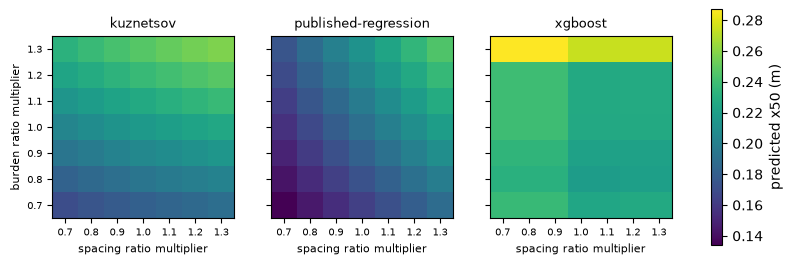

In [5]:
# The three response surfaces on a shared colour scale
low = min(np.nanmin(g) for g in surface.values())
high = max(np.nanmax(g) for g in surface.values())
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
for ax, (name, grid) in zip(axes, surface.items()):
    image = ax.imshow(grid, origin="lower", vmin=low, vmax=high, cmap="viridis")
    ax.set_xticks(range(7), [f"{f:.1f}" for f in factors], fontsize=7)
    ax.set_yticks(range(7), [f"{f:.1f}" for f in factors], fontsize=7)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("spacing ratio multiplier", fontsize=8)
axes[0].set_ylabel("burden ratio multiplier", fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.85, label="predicted x50 (m)")
plt.show()

## Results

**The classical surface is exactly what the equation says.** The slope of the log mean size against the log volume equals 1/6 to six digits, so the surface is a single smooth power of the volume: it rises with both the burden and the spacing, and the two levers trade off along lines of constant volume. Nothing in it is learned.

**The regression is smooth too, with other exponents.** It takes a different value at each of the 49 points, with the exponents that Hudaverdi et al. fitted, and covers a slightly different range of sizes than the classical surface (see the table above).

**The learned surface is a staircase.** Gradient boosting returns only the values its leaves hold, so the 49 grid points collapse into far fewer distinct values than the other two arms produce (the count is in the table above), and neighbouring designs share a prediction. This is not an error; it is what a tree ensemble on 85 rows can say. It also means the learned arm's response to a design change is much coarser than its scoring suggests.

**What this does not show.** All three surfaces are model responses on one blast from one site. They cover different ranges of size, and no dataset records the effect of changing a lever at a given pit, so none of them can be called the right one. The surface answers "what does this model say", not "what will the muckpile look like".

## Summary

- Two `apply_variant` calls make a grid point; `is_degenerate` guards it; every arm predicts it.
- The classical surface follows the equation (slope 1/6 against the log volume), the regression is a smooth power law with other exponents, and a tree ensemble is a staircase.
- The surfaces differ more among themselves than any lever moves any of them, and none is validated against an observed response.
- Next: notebook 03 shows how the learned arms are served live from a portable document (level 4).

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the published regression)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (the classical equation, whose volume dependence is checked here)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (gradient boosting)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/